# 01. 최종 제출 파일 재현과 평가 (CPU)

팀 못나지않은사람들 · KoAltQ · 리더보드 0.9357 (이진 F1 0.9579 / macro-F1 0.9134)

이 노트북은 `model/runs_frozen/`에 저장된 각 모델의 출력(OOF·test 확률)에서 **최종 결정 단계(결합 → 할당량 → 하네스)** 를 다시 실행합니다.
그 결과가 `submission/final_submission_0.9357.csv`와 바이트 단위로 같은지 확인하고, 모델별 검증 성능과 결과 그림을 보여 줍니다.

| 순서 | 내용 |
|---|---|
| 1 | 데이터 불러오기 (학습 2,400 · 평가 600 · 공개 경계사례 109) |
| 2 | 결정 단계 실행 (`scripts/reproduce_best.sh`, CPU 3~8분) |
| 3 | 제출 파일과 대조 (sha256) |
| 4 | 평가: 모델별 5-fold OOF 성능, 결합 규칙 선택 근거, 혼동행렬 |
| 5 | 하네스 감사 로그 |
| 6 | 결과 그림 (figures/에도 저장) |
| 7 | (선택) 하네스 실험 |

- 필요 환경: `requirements.txt` (+ 로컬 실행 시 `requirements-notebook.txt`). GPU는 필요 없습니다.
- 학습 단계 전체(GPU)는 `02_full_pipeline_colab.ipynb`를 봅니다.
- Colab에서는 제출물 폴더를 `/content/KoAltQ_submission_0.9357`에 풀면 아래 셀이 자동으로 찾습니다.

In [1]:
import collections, csv, hashlib, json, os, subprocess, sys, time
from pathlib import Path

cands = [Path.cwd(), Path.cwd().parent, Path("/content/KoAltQ_submission_0.9357")]
ROOT = next((p for p in cands if (p / "src" / "koaltq2").exists()), None)
assert ROOT is not None, "제출물 폴더(또는 그 안의 notebooks/)에서 실행하거나 /content/KoAltQ_submission_0.9357 에 풀어 주세요"
os.environ["KOALTQ_BUNDLE"] = str(ROOT / "data" / "koaltq_bundle")
os.environ["KOALTQ_RUNS"] = str(ROOT / "model" / "runs_frozen")   # 읽기만 함 (재현은 임시 복사본에서 실행)
sys.path.insert(0, str(ROOT / "src"))
print("ROOT:", ROOT, "| python", sys.version.split()[0])

ROOT: /content/pkg_test2/KoAltQ_submission_0.9357 | python 3.13.16


## 1. 데이터 불러오기

`src/koaltq2/common.py`의 `Data`가 번들을 읽습니다.
- 행 수(2,400 / 600), fold 파일 sha256, 공개 경계사례 109건을 검사합니다.
- 전처리(이미지 정규화)는 번들을 만들 때 끝냈습니다(`data/README.md`).
- 각 단계의 텍스트·구조 특징은 모듈 안에서 계산합니다.

In [2]:
from koaltq2.common import Data, LABELS

data = Data()
print("train", len(data.train), "| test", len(data.test), "| public boundary rows (test)", len(data.boundary_test))
print("train labels:", dict(collections.Counter(LABELS[i] for i in data.y)))
print("5-fold sizes:", dict(sorted(collections.Counter(int(f) for f in data.folds).items())))
print("record fields:", list(data.test[0].keys()))

train 2400 | test 600 | public boundary rows (test) 109
train labels: {'무관형': 15, '불충분형': 564, '적절': 1599, '중복형': 146, '파일명형': 26, '무의미형': 24, '장식오용형': 26}
5-fold sizes: {0: 458, 1: 524, 2: 454, 3: 468, 4: 496}
record fields: ['record_id', 'page_url', 'page_title', 'kogl_marker', 'image_url', 'image_file', 'alt_text', 'context_text', 'in_link', 'link_dest', 'heading_path']


## 2. 결정 단계 실행

`scripts/reproduce_best.sh`가 하는 일:
1. `model/runs_frozen`을 임시 폴더로 복사하고, 스태커의 test 확률을 x17fx로 교체합니다.
   - x17fx: 같은 LightGBM 레시피를 rot1·rot6 판정기 이후(특징 378개)에 학습 2,400 + 공개 109 + 규칙 확정 test 133행으로 학습한 모델
2. `python -m koaltq2.run x8 --objective lbq --wlora 0.4`를 `KOALTQ_HARNESS=1`로 실행합니다.
   - 결합: 0.6 × (0.9 log P스태커 + 0.1 log P판정기LR) + 0.4 × 평균 log P(27B·9B LoRA)
   - 할당량: 규칙으로 정하지 않은 행에 평가셋 클래스 분포를 맞춰 배정
   - 하네스 H0~H5
3. 결과를 `outputs/`에 저장하고 sha256을 대조합니다.

In [3]:
t0 = time.time()
env = dict(os.environ, PYTHON=sys.executable)
proc = subprocess.run(["bash", str(ROOT / "scripts" / "reproduce_best.sh")], cwd=ROOT, env=env, capture_output=True, text=True)
log = proc.stdout + proc.stderr
keep = [l for l in log.splitlines() if l.startswith(("  per-fold honest quota sim", "  lora grid", "[x8] harness", "reproduced", "sha256", "OK", "MISMATCH", "[run]"))]
print("\n".join(k[:400] for k in keep))
print(f"elapsed {time.time() - t0:.0f}s, return code {proc.returncode}")
assert proc.returncode == 0, log[-3000:]

[run] x8 start 01:05:12 args=['--objective', 'lbq', '--wlora', '0.4']
  per-fold honest quota sim: {'caruana': 0.8669, 'single': 0.866, 'blend:x17_stack_lgbm_b109': 0.8811, 'blend:x7_stack_hgb': 0.8577, 'blend:x7_stack_lgbm': 0.8612, 'blend:x7j_stack_hgb': 0.8725, 'blend:x7j_stack_lgbm': 0.8779} -> rule blend:x17_stack_lgbm_b109
  lora grid (fold0): {'0.0': 0.8709, '0.2': 0.8817, '0.4': 0.8809, '0.6': 0.8719} -> w_lora 0.4
[x8] harness: {"H0_public_row | applied": 109, "H1_R1_filename_cascade | applied": 8, "H1_R2_restoration_role_marker | applied": 116, "H2_template_twins | applied": 17, "H3_sole_link_never_decoration | applied": 1, "H4_structure_twins | applied": 6, "H4_structure_twins+H5a_original_labelers_never_give_it | not applied": 2, "H4_structure_twins+H5b_blend_and_judge_both_confident | not applied": 1}
[run] x8 DONE in 456.8s
reproduced: /content/pkg_test2/KoAltQ_submission_0.9357/outputs/reproduced_submission.csv
sha256 87c3de688bd20937dc86abb9fb5e1171d6d012cd132aa23bd1c3f

## 3. 제출 파일과 대조

In [4]:
def read(p):
    return {r["record_id"]: r["label"] for r in csv.DictReader(open(p, encoding="utf-8-sig"))}

sub = read(ROOT / "submission" / "final_submission_0.9357.csv")
rep = read(ROOT / "outputs" / "reproduced_submission.csv")
sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()
print("rows:", len(rep), "| label differences vs submission:", sum(sub[k] != rep[k] for k in sub))
print("sha256 submission :", sha(ROOT / "submission" / "final_submission_0.9357.csv"))
print("sha256 reproduced :", sha(ROOT / "outputs" / "reproduced_submission.csv"))
print("final class counts:", dict(collections.Counter(rep.values())))

rows: 600 | label differences vs submission: 0
sha256 submission : 87c3de688bd20937dc86abb9fb5e1171d6d012cd132aa23bd1c3f9611a9a1cf8
sha256 reproduced : 87c3de688bd20937dc86abb9fb5e1171d6d012cd132aa23bd1c3f9611a9a1cf8
final class counts: {'적절': 415, '불충분형': 128, '중복형': 35, '장식오용형': 5, '무관형': 4, '무의미형': 5, '파일명형': 8}


## 4. 평가

### 4-1. 모델별 검증 성능 (학습 데이터 5-fold OOF)

- 각 모델의 fold 밖 예측을 학습 라벨과 비교한 값입니다(`metrics.json`).
- 대회 지표 = 0.5 × 이진 F1 + 0.5 × macro-F1
- LoRA는 fold 0(458행) 검증만 했습니다.
- 평가 데이터의 실제 성능은 리더보드(0.9357)로 확인했습니다. 평가 데이터에는 공개 109행과 규칙 확정 행이 포함되어 있어 OOF보다 높습니다.

In [5]:
R = ROOT / "model" / "runs_frozen"
models = [("x1_hgb", "rules + TF-IDF features -> HGB"), ("x2_hgb_ocr", "OCR features -> HGB"),
          ("x3_qwen35_9b_lr", "Qwen3.5-9B embedding -> LR"), ("x3_internvl35_14b_lr", "InternVL3.5-14B embedding -> LR"),
          ("x7j_stack_lgbm", "stacker with judge features"), ("x15_judge_lr", "judge LR (blend weight 0.1)"),
          ("x17_stack_lgbm_b109", "final stacker x17 (blend weight 0.9)"),
          ("x6_qwen35_9b_lora_fold", "Qwen3.5-9B LoRA (fold 0)"), ("x6_qwen38_27b_lora_fold", "Qwen3.8-27B LoRA (fold 0)")]
print(f"{'run':26s} {'model':40s} {'n':>5s} {'composite':>9s} {'binary F1':>9s} {'macro F1':>9s}")
for name, role in models:
    m = json.load(open(R / name / "metrics.json", encoding="utf-8"))
    o = m["oof"] if m["oof"].get("n", 0) == 2400 else m["oof_fold0"]
    print(f"{name:26s} {role:40s} {o['n']:5d} {o['composite']:9.4f} {o['binary_f1']:9.4f} {o['macro_f1']:9.4f}")

run                        model                                        n composite binary F1  macro F1
x1_hgb                     rules + TF-IDF features -> HGB            2400    0.5907    0.7026    0.4789
x2_hgb_ocr                 OCR features -> HGB                       2400    0.6435    0.7793    0.5077
x3_qwen35_9b_lr            Qwen3.5-9B embedding -> LR                2400    0.5853    0.6943    0.4762
x3_internvl35_14b_lr       InternVL3.5-14B embedding -> LR           2400    0.5863    0.6939    0.4787
x7j_stack_lgbm             stacker with judge features               2400    0.7763    0.8361    0.7165
x15_judge_lr               judge LR (blend weight 0.1)               2400    0.6881    0.7342    0.6421
x17_stack_lgbm_b109        final stacker x17 (blend weight 0.9)      2400    0.7697    0.8357    0.7036
x6_qwen35_9b_lora_fold     Qwen3.5-9B LoRA (fold 0)                   458    0.5948    0.6891    0.5004
x6_qwen38_27b_lora_fold    Qwen3.8-27B LoRA (fold 0)            

### 4-2. 결합 규칙 선택 근거 (x8 결정 단계)

후보마다 학습 OOF로 '정직한 fold별 할당량 시뮬레이션' 점수를 계산합니다.
- 각 fold를 따로 떼어 할당량 배정을 흉내 내고 대회 지표를 냅니다.
- 가장 높은 규칙을 고릅니다.
- LoRA 혼합 비중은 fold 0 격자에서 0.4를 썼습니다.

In [6]:
rep_json = json.load(open(ROOT / "outputs" / "report.json", encoding="utf-8"))
for k in ("rule", "perfold_quota", "lora_grid_fold0", "ensemble_weights", "residual_target"):
    if k in rep_json:
        v = rep_json[k]
        if k == "perfold_quota":
            v = {r: round(x["mean"], 4) for r, x in v.items()}
        print(f"{k}: {v}")

rule: {'name': 'blend:x17_stack_lgbm_b109', 'a': 0.1}
perfold_quota: {'caruana': 0.8669, 'single': 0.866, 'blend:x17_stack_lgbm_b109': 0.8811, 'blend:x7_stack_hgb': 0.8577, 'blend:x7_stack_lgbm': 0.8612, 'blend:x7j_stack_hgb': 0.8725, 'blend:x7j_stack_lgbm': 0.8779}
lora_grid_fold0: {'0.0': 0.8709, '0.2': 0.8817, '0.4': 0.8809, '0.6': 0.8719}
ensemble_weights: {'x15_judge_lr': 0.1, 'x17_stack_lgbm_b109': 0.9}
residual_target: {'적절': 257, '무의미형': 4, '파일명형': 0, '중복형': 33, '장식오용형': 2, '불충분형': 50, '무관형': 4}


### 4-3. 최종 스태커(x17)의 OOF 혼동행렬

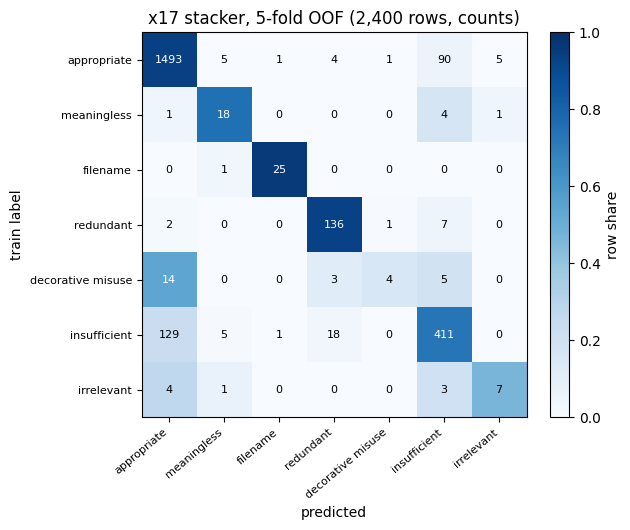

In [7]:
import numpy as np
import matplotlib.pyplot as plt

EN = {"적절": "appropriate", "무의미형": "meaningless", "파일명형": "filename", "중복형": "redundant",
      "장식오용형": "decorative misuse", "불충분형": "insufficient", "무관형": "irrelevant"}
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
cm = np.array(json.load(open(R / "x17_stack_lgbm_b109" / "metrics.json", encoding="utf-8"))["confusion_oof"])
fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(7):
    for j in range(7):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8, color="white" if cm[i, j] / cm[i].sum() > 0.5 else "black")
ax.set_xticks(range(7)); ax.set_xticklabels([EN[l] for l in LABELS], rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(7)); ax.set_yticklabels([EN[l] for l in LABELS], fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("train label"); ax.set_title("x17 stacker, 5-fold OOF (2,400 rows, counts)")
fig.colorbar(im, ax=ax, fraction=0.046, label="row share")
fig.tight_layout(); fig.savefig(FIG / "confusion_x17_oof.png", dpi=150); plt.show()

## 5. 하네스 감사 로그

`outputs/harness_log.jsonl`에는 규칙이 결정한 모든 행이 근거와 함께 기록됩니다.
- 기록 항목: 모듈, 바꾸기 전/후 라벨, 적용 여부, 학습 구조 통계, 결합 모델·판정기 확률
- 기록되지 않은 행은 모델(결합 + 할당량)이 정한 라벨입니다.

In [8]:
summary = json.load(open(ROOT / "outputs" / "harness_summary.json", encoding="utf-8"))
for k, v in summary.items():
    print(f"{v:4d}  {k}")
log_rows = [json.loads(l) for l in open(ROOT / "outputs" / "harness_log.jsonl", encoding="utf-8")]
print("\nH4/H5 decisions (structure twins and the audit-agreement veto):")
for e in log_rows:
    if e["module"].startswith("H4"):
        print({k: e[k] for k in ("module", "before", "after", "applied", "train_struct_n", "train_share_current", "blend_p_current", "judge_p_current")})

 109  H0_public_row | applied
   8  H1_R1_filename_cascade | applied
 116  H1_R2_restoration_role_marker | applied
  17  H2_template_twins | applied
   1  H3_sole_link_never_decoration | applied
   6  H4_structure_twins | applied
   2  H4_structure_twins+H5a_original_labelers_never_give_it | not applied
   1  H4_structure_twins+H5b_blend_and_judge_both_confident | not applied

H4/H5 decisions (structure twins and the audit-agreement veto):
{'module': 'H4_structure_twins', 'before': '불충분형', 'after': '적절', 'applied': True, 'train_struct_n': 5, 'train_share_current': 0.4, 'blend_p_current': 0.941, 'judge_p_current': 0.733}
{'module': 'H4_structure_twins+H5a_original_labelers_never_give_it', 'before': '불충분형', 'after': '적절', 'applied': False, 'train_struct_n': 29, 'train_share_current': 1.0, 'blend_p_current': 0.984, 'judge_p_current': 0.345}
{'module': 'H4_structure_twins', 'before': '불충분형', 'after': '적절', 'applied': True, 'train_struct_n': 5, 'train_share_current': 0.4, 'blend_p_current':

## 6. 결과 그림

그림은 `figures/`에도 저장합니다. 한글 글꼴이 없는 환경을 위해 범주 이름은 영어로 표기합니다.
- 적절 = appropriate, 무의미형 = meaningless, 파일명형 = filename, 중복형 = redundant
- 장식오용형 = decorative misuse, 불충분형 = insufficient, 무관형 = irrelevant

리더보드 점수 변화 중 일부 값은 대응 관계가 추정입니다.
- 0.8379, 0.8875: 제출 이력의 소수 둘째 자리(0.84, 0.89)와 리더보드 표시를 대응시킨 추정

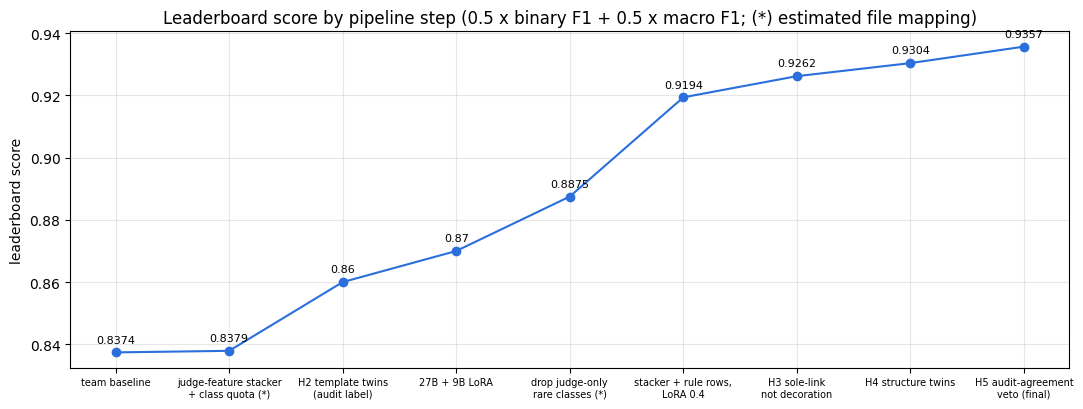

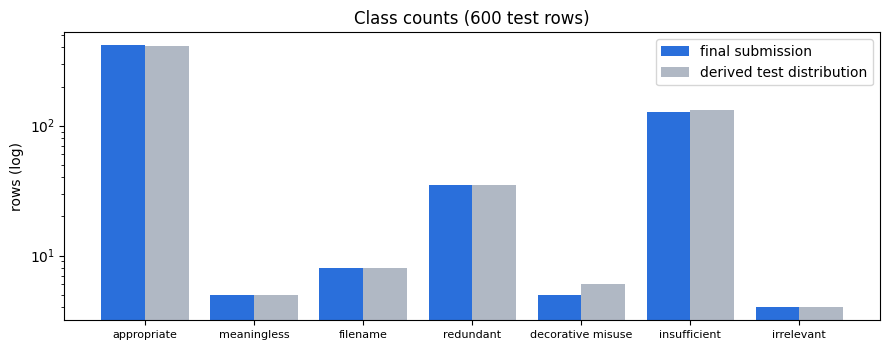

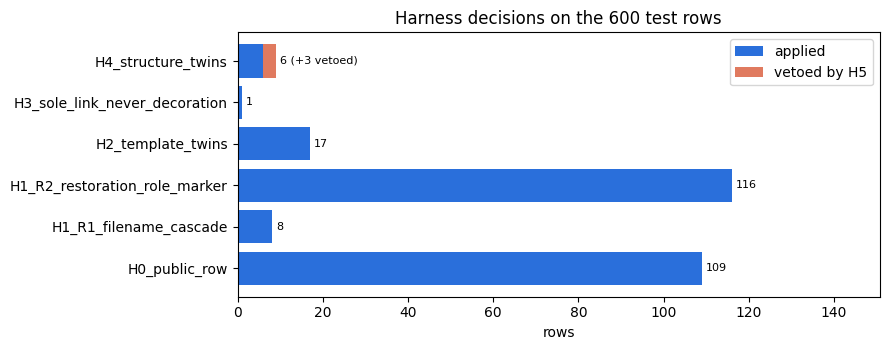

saved: ['class_counts.png', 'confusion_x17_oof.png', 'harness_modules.png', 'lb_progression.png']


In [9]:
steps = [("team baseline", 0.8374), ("judge-feature stacker\n+ class quota (*)", 0.8379), ("H2 template twins\n(audit label)", 0.86),
         ("27B + 9B LoRA", 0.87), ("drop judge-only\nrare classes (*)", 0.8875), ("stacker + rule rows,\nLoRA 0.4", 0.9194),
         ("H3 sole-link\nnot decoration", 0.9262), ("H4 structure twins", 0.9304), ("H5 audit-agreement\nveto (final)", 0.9357)]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(range(len(steps)), [s for _, s in steps], marker="o", color="#2a6fdb")
for i, (_, s) in enumerate(steps):
    ax.annotate(f"{s:.4f}".rstrip("0"), (i, s), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set_xticks(range(len(steps))); ax.set_xticklabels([n for n, _ in steps], fontsize=7)
ax.set_ylabel("leaderboard score"); ax.grid(alpha=0.3)
ax.set_title("Leaderboard score by pipeline step (0.5 x binary F1 + 0.5 x macro F1; (*) estimated file mapping)")
fig.tight_layout(); fig.savefig(FIG / "lb_progression.png", dpi=150); plt.show()

derived = {"적절": 409, "무의미형": 5, "파일명형": 8, "중복형": 35, "장식오용형": 6, "불충분형": 133, "무관형": 4}
cnt = collections.Counter(rep.values()); labs = list(derived); x = range(len(labs))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar([i - 0.2 for i in x], [cnt[l] for l in labs], width=0.4, label="final submission", color="#2a6fdb")
ax.bar([i + 0.2 for i in x], [derived[l] for l in labs], width=0.4, label="derived test distribution", color="#b0b8c4")
ax.set_xticks(list(x)); ax.set_xticklabels([EN[l] for l in labs], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("rows (log)"); ax.legend(); ax.set_title("Class counts (600 test rows)")
fig.tight_layout(); fig.savefig(FIG / "class_counts.png", dpi=150); plt.show()

mods = collections.Counter((e["module"].split("+")[0], e["applied"]) for e in log_rows)
names = ["H0_public_row", "H1_R1_filename_cascade", "H1_R2_restoration_role_marker", "H2_template_twins",
         "H3_sole_link_never_decoration", "H4_structure_twins"]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(names, [mods[(n, True)] for n in names], color="#2a6fdb", label="applied")
ax.barh(names, [mods[(n, False)] for n in names], left=[mods[(n, True)] for n in names], color="#e07a5f", label="vetoed by H5")
for i, n in enumerate(names):
    ax.text(mods[(n, True)] + mods[(n, False)] + 1, i, str(mods[(n, True)]) + (f" (+{mods[(n, False)]} vetoed)" if mods[(n, False)] else ""), va="center", fontsize=8)
tot = max(mods[(n, True)] + mods[(n, False)] for n in names)
ax.set_xlim(0, tot * 1.3); ax.set_xlabel("rows"); ax.set_title("Harness decisions on the 600 test rows"); ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "harness_modules.png", dpi=150); plt.show()
print("saved:", sorted(p.name for p in FIG.glob("*.png")))

## 7. (선택) 하네스 실험

`bash scripts/run_harness_experiments.sh`는 다음을 실행하고 `outputs/`에 결과를 남깁니다.
- 동료 설계 H6 서명 투표 3종
- 학습 데이터 시뮬레이션(검증 하네스)
- conformal 예측집합 분석

아래 셀은 `RUN_EXPERIMENTS = True`일 때만 실행합니다(약 1분).

In [10]:
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    proc = subprocess.run(["bash", str(ROOT / "scripts" / "run_harness_experiments.sh")], cwd=ROOT, env=env, capture_output=True, text=True)
    print("\n".join(l for l in (proc.stdout + proc.stderr).splitlines() if l.startswith(("[hval]", "HARNESS_"))))